# ЛР3. Анализ: можно ли доверять LLM в задачах классического ML

Из этого ноутбука берётся **каждое число отчёта** (шаг 9 хода работы). Ноутбук только читает файлы:
`results/` (ответы, автопроверка, запуски кода D, тип E), `grading/` (листы двух проверяющих и ключ),
`logs/calls.jsonl` (память локальной модели), `config/` (модели, тарифы, настройки). Все числа экспортируются
в `results/summary_metrics.json`, рисунки — в `report/figures/`.

Логика подсчёта вынесена в `src/analysis.py` (там же правила: что считается «верно», как учитываются отказы
и расхождения проверяющих); функции покрыты тестами `tests/test_analysis.py`. Здесь — вызовы и комментарии.



Запуск: Kernel → Restart & Run All, или
`.venv/bin/jupyter nbconvert --to notebook --execute --inplace analysis.ipynb`.

`DEMO = True` — проверка ноутбука на mock-моделях и случайных оценках из `demo/` (чисел для отчёта там нет;
на каждом рисунке и таблице пометка DEMO, файлы пишутся в `demo/`).

In [1]:
DEMO = False   # True — демо-данные из demo/ (mock-модели, случайные оценки). Для отчёта всегда False.

## 0. Настройки и загрузка

In [2]:
import json
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import analysis as an, autograde, bank, checks, llm, run_bank, typeE

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

P = an.paths(DEMO)                      # пути: results/, grading/, журнал, рисунки, summary
CFG = run_bank.load_experiment()        # config/experiment.json
SEED = CFG["seed"]                      # 42: бутстреп и всё случайное
N_BOOT = CFG["bootstrap_n"]             # 1000 ресэмплов задач
LANG = CFG["languages"][0]              # язык основного прогона (ru)
SELECTED = CFG["hypotheses"]            # выбранные гипотезы (закоммичены до прогонов)
MODELS = llm.load_models()              # config/models.json: роль модели → цвет и группа (H4, H5)
PRICING = an.load_pricing(P["pricing"]) # config/pricing.json
TAG = an.demo_label(DEMO)               # пометка DEMO в заголовках рисунков

summary = {"demo": DEMO, "inputs": an.input_fingerprints(P), "hypotheses_selected": SELECTED,
           "seed": SEED, "bootstrap_n": N_BOOT, "coverage": {}}
if DEMO:
    print("=" * 70 + "\nDEMO: mock-модели и случайные оценки. Это НЕ результаты эксперимента.\n" + "=" * 70)
print("Выбранные гипотезы:", SELECTED or "ещё не выбраны (config/experiment.json)")
print("Входные файлы:", *summary["inputs"], sep="\n  ")

Выбранные гипотезы: ['H1', 'H6', 'H9']
Входные файлы:
  results\cot_ru.jsonl
  results\d_exec.jsonl
  results\followup_doubt_ru.jsonl
  results\graded_auto.jsonl
  results\main_ru.jsonl
  results\typeE_llm.jsonl
  results\typeE_classical.csv
  results\typeE_metrics.csv
  grading\key_DO_NOT_OPEN.csv
  grading\parser_spotcheck.csv
  grading\parser_spotcheck_filled.csv
  grading\sheet_r1.csv
  grading\sheet_r1_scored.csv
  grading\sheet_r2.csv
  grading\sheet_r2_scored.csv
  config\pricing.json
  config\experiment.json
  logs\calls.jsonl


In [3]:
# Методика: состав банка (data/tasks.jsonl) и вызовы моделей (журнал) — отсюда эти числа берёт отчёт.
summary["bank"] = an.bank_summary(bank.load_tasks(bank.BANK_PATH))
summary["runs"] = an.runs_summary(P["log"], MODELS)
print(f"Банк: {summary['bank']['n_tasks']} задач, своих {summary['bank']['n_own']}; статусы эталонов: {summary['bank']['status']}")
an.show(summary["bank"]["tables"]["тип × тема"], "Банк: тип × тема", DEMO, floatfmt="{:.0f}")
an.show(pd.DataFrame([{"experiment": k, **v} for k, v in summary["runs"]["calls_by_experiment"].items()]),
        "Вызовы по экспериментам (журнал)", DEMO, floatfmt="{:.0f}")
an.show(pd.DataFrame([{"model_key": k, **v} for k, v in summary["runs"]["models"].items()]),
        "Модели: идентификаторы, даты, параметры (без smoke и dev)", DEMO)

Банк: 38 задач, своих 20; статусы эталонов: {'agent_draft': 0, 'verified': 38, 'todo': 0}
Банк: тип × тема


topic,type,bayes,clustering,ensembles,knn,linreg,logreg,metrics,pca,svm,trees,всего
0,A,1,0,0,1,1,1,1,1,1,1,8
1,B,1,1,1,1,1,1,1,1,0,0,8
2,C,1,1,1,0,0,1,0,1,1,0,6
3,D,0,1,1,1,1,0,0,1,1,0,6
4,F,1,1,1,1,1,1,1,1,1,1,10
5,всего,4,4,4,4,4,4,3,5,4,2,38


Вызовы по экспериментам (журнал)


,experiment,first_utc,last_utc,records,ok,errors,retried_requests,unresolved_requests
0,cot,2026-10-15T00:43:04.928+00:00,2026-10-15T09:52:10.102+00:00,111,80,31,3,0
1,dev,2026-10-09T22:22:38.530+00:00,2026-10-14T18:28:36.484+00:00,110,110,0,0,0
2,followup_doubt,2026-10-15T01:22:28.418+00:00,2026-10-15T09:52:56.023+00:00,88,88,0,0,0
3,main,2026-10-15T00:39:12.717+00:00,2026-10-15T00:42:47.868+00:00,152,152,0,0,0
4,smoke,2026-10-09T17:52:54.153+00:00,2026-10-16T00:55:48.993+00:00,69,59,10,3,0
5,typeE,2026-10-15T03:19:10.759+00:00,2026-10-15T10:22:30.275+00:00,2400,2400,0,0,0


Модели: идентификаторы, даты, параметры (без smoke и dev)


,model_key,provider,model_requested,model_reported,params,effective_temperature,min_temperature,max_tokens,experiments,first_utc,last_utc,records,ok,errors,retried_requests,unresolved_requests,tokens_in,tokens_out,finish_reason_length,periods,ollama_base_url,local_vram_mb_max,local_model_size_mb_max
0,deepseek-v4-pro,openai_compat,[deepseek-v4-pro],[deepseek-v4-pro],[{'extra_body': {'thinking': {'type': 'disable...,[0.0],0.000,[None],"[cot, followup_doubt, main, typeE]",2026-10-15T00:39:12.717+00:00,2026-10-15T10:22:30.275+00:00,711,680,31,3,0,524055,190052,0,{'cot': {'first_utc': '2026-10-15T00:43:04.928...,NaN,NaN,NaN
1,gigachat-2-max,gigachat,[GigaChat-2-Max],[GigaChat-2-Max:2.0.30.01],[{}],[0.0001],0.000,[None],"[cot, followup_doubt, main, typeE]",2026-10-15T00:39:12.717+00:00,2026-10-15T03:45:11.965+00:00,675,675,0,0,0,76241,104429,0,{'cot': {'first_utc': '2026-10-15T00:43:04.928...,NaN,NaN,NaN
2,qwen3-8b,ollama,[qwen3:8b],[qwen3:8b],"[{'options': {'num_ctx': 8192}, 'think': False}]",[0.0],0.000,[None],"[cot, followup_doubt, main, typeE]",2026-10-15T00:39:12.717+00:00,2026-10-15T03:51:24.280+00:00,673,673,0,0,0,650912,259340,0,{'cot': {'first_utc': '2026-10-15T00:43:04.928...,[http://localhost:11435],4983.300,4983.300
3,qwen3-8b-think,ollama,[qwen3:8b],[qwen3:8b],"[{'options': {'num_ctx': 16384}, 'think': True}]",[0.0],0.000,[None],[cot],2026-10-15T00:44:22.632+00:00,2026-10-15T00:46:49.569+00:00,16,16,0,0,0,5056,17936,0,{'cot': {'first_utc': '2026-10-15T00:44:22.632...,[http://localhost:11435],4983.300,4983.300
4,yandexgpt-pro-5.1,openai_compat,[gpt://b1gefd33pbo1ekddusqe/yandexgpt-5.1],[gpt://b1gefd33pbo1ekddusqe/yandexgpt-5.1],[{}],[0.0],0.000,[None],"[cot, followup_doubt, main, typeE]",2026-10-15T00:39:12.717+00:00,2026-10-15T03:26:35.912+00:00,676,676,0,0,0,481381,73189,0,{'cot': {'first_utc': '2026-10-15T00:43:04.928...,NaN,NaN,NaN


### 0.1. Ручные оценки: два проверяющих, деанонимизация по ключу

Листы `sheet_r1.csv` и `sheet_r2.csv` соединяются с ключом `key_DO_NOT_OPEN.csv` по `item_id` — так у каждой
оценки появляются модель, задача и `call_id`. Итоговая оценка = **среднее двух проверяющих**
(для «верно / неверно» получается 0, 0,5 или 1). Ниже — список всех расхождений.

In [4]:
manual = an.load_manual(P["grading"])
if manual.empty:
    print("Листов ручной проверки нет: C и D пока без оценки (G2 в HUMAN_TODO.md).")
else:
    n_incomplete = int((~manual["complete"]).sum())
    print(f"Строк в листах: {len(manual)}; заполнены обоими полностью: {len(manual) - n_incomplete}")
    if n_incomplete:
        print(f"  ВНИМАНИЕ: {n_incomplete} строк заполнены не до конца — такие ответы C/D не входят в точность")
disagree = an.disagreements(manual) if not manual.empty else pd.DataFrame()
an.show(disagree, f"Расхождения проверяющих (всего {len(disagree)})", DEMO)

Строк в листах: 80; заполнены обоими полностью: 80
Расхождения проверяющих (всего 0)
  нет данных


### 0.2. Ответы основного прогона

Одна строка на ответ модели (`results/main_<lang>.jsonl`). `correct`: A, F, вердикт B — автопроверка
(`results/graded_auto.jsonl`, ответ разобран заново и сравнён с текущим эталоном); C — доля проверяющих,
поставивших балл ≥ 1; D — доля проверяющих, отметивших «итоговая метрика верна» (если автопроверка уже нашла
метрику в допуске, то 1). Ответы с технической ошибкой (сеть, 429, 5xx) не являются ответами модели и не входят.

In [5]:
graded = an.read_table(P["results"], "graded_auto")
main, n_tech = an.answers(P["results"], "main", LANG, manual, graded)
HAVE_MAIN = not main.empty
if HAVE_MAIN:
    main = an.add_full_input(main, P["log"], MODELS)       # tokens_in_full: у GigaChat + токены из кэша (журнал)
    ORDER = an.order_models(main["model_key"], MODELS)      # порядок моделей: ru1, ru2, big, local
    COLORS = [an.model_color(m, MODELS) for m in ORDER]
    ungraded = main[main["correct"].isna()]
    print(f"Ответов: {len(main)} (моделей {len(ORDER)}, задач {main['task_id'].nunique()}); "
          f"техошибок (не входят): {n_tech}")
    print(f"Без оценки (в точность не входят): C/D без ручной оценки — {int(ungraded['type'].isin(['C', 'D']).sum())}, "
          f"A/B/F без автопроверки (нет эталона) — {int((~ungraded['type'].isin(['C', 'D'])).sum())}")
    print("Модели:", ", ".join(f"{m} ({MODELS.get(m, {}).get('role')})" for m in ORDER))
    print("model_reported:", {m: sorted(map(str, g.unique())) for m, g in main.groupby("model_key")["model_reported"]})
else:
    ORDER, COLORS = [], []
    print(f"Нет {run_bank.show(P['results'] / f'main_{LANG}.jsonl')}: основной прогон ещё не сделан (шаг 08).")
summary["counts"] = {"main_answers": len(main), "main_tech_errors": n_tech,
                     "main_ungraded": int(main["correct"].isna().sum()) if HAVE_MAIN else 0,
                     "models": ORDER, "manual_rows": len(manual), "disagreements": len(disagree)}

Ответов: 152 (моделей 4, задач 38); техошибок (не входят): 0
Без оценки (в точность не входят): C/D без ручной оценки — 0, A/B/F без автопроверки (нет эталона) — 0
Модели: gigachat-2-max (ru1), yandexgpt-pro-5.1 (ru2), deepseek-v4-pro (big), qwen3-8b (local)
model_reported: {'deepseek-v4-pro': ['deepseek-v4-pro'], 'gigachat-2-max': ['GigaChat-2-Max:2.0.30.01'], 'qwen3-8b': ['qwen3:8b'], 'yandexgpt-pro-5.1': ['gpt://b1gefd33pbo1ekddusqe/yandexgpt-5.1']}


### 0.3. Выборочная проверка парсера (20 ответов, `grading/parser_spotcheck.csv`)

Доля «да» (человек согласен с разбором и автооценкой) отдельно для случайных и для «подозрительных» ответов.

In [6]:
spot_path = P["grading"] / autograde.SPOTCHECK_NAME
spot = pd.DataFrame(autograde.read_csv(spot_path)) if spot_path.exists() else pd.DataFrame()
if not spot.empty:
    spot["agree"] = spot["human_agrees"].map(checks.norm)
    spot = spot[spot["agree"].isin(["да", "нет"])]       # только строки, где человек ответил «да» или «нет»
if spot.empty:
    print("Выборочная проверка парсера ещё не заполнена (G2 в HUMAN_TODO.md).")
    spot_table = pd.DataFrame()
else:
    spot_table = (spot.groupby("selection")["agree"]
                  .agg(n="size", n_yes=lambda s: int((s == "да").sum())).reset_index())
    spot_table["share_yes"] = spot_table["n_yes"] / spot_table["n"]
    spot_table[["ci_low", "ci_high"]] = [an.clopper_pearson(k, n) for k, n in zip(spot_table["n_yes"], spot_table["n"])]
an.show(spot_table, "Согласие человека с автопарсером (CI Клоппера–Пирсона)", DEMO)
summary["parser_spotcheck"] = spot_table

Согласие человека с автопарсером (CI Клоппера–Пирсона)


,selection,n,n_yes,share_yes,ci_low,ci_high
0,подозрительный,6,6,1.000,0.541,1.000
1,подозрительный E,4,0,0.000,0.000,0.602
2,случайный,10,8,0.800,0.444,0.975


## 1. Согласие проверяющих: каппа Коэна

`sklearn.metrics.cohen_kappa_score` по клеткам, заполненным обоими: B и C — балл 0–2, D — все пункты чек-листа
вместе (1 / 0 / н/п) и по отдельности, корректность метрики D (где её ставили люди). Если κ < 0,6 —
уточнить рубрику и переоценить (задание).

In [7]:
kappa = an.kappa_table(manual)
an.show(kappa, "Каппа Коэна", DEMO)
low = kappa[kappa["below_min"]] if not kappa.empty else kappa
if len(low):
    print("\n" + "!" * 70)
    print(f"ВНИМАНИЕ: κ < {an.KAPPA_MIN} — " + "; ".join(f"{r.type}: {r.what} (κ = {r.kappa:.2f})" for r in low.itertuples()))
    print("Нужно уточнить рубрику и переоценить (HUMAN_TODO, G2). Числа C/D ниже пока ненадёжны.")
    print("!" * 70)
summary["kappa"] = kappa
summary["kappa_below_min"] = low["type"].tolist() if len(low) else []

Каппа Коэна


,type,what,n_pairs,agreement,kappa,below_min
0,B,балл 0–2,32,1.000,1.000,False
1,C,балл 0–2,24,1.000,1.000,False
2,D,чек-лист (все пункты),144,1.000,1.000,False
3,D,чек-лист: масштабирование/препроцессинг до раз...,24,1.000,NaN,False
4,D,чек-лист: подбор гиперпараметров по тесту,24,1.000,1.000,False
5,D,чек-лист: оценка на обучающей выборке,24,1.000,NaN,False
6,D,чек-лист: accuracy при сильном дисбалансе,24,1.000,1.000,False
7,D,чек-лист: нет стратификации,24,1.000,1.000,False
8,D,чек-лист: не зафиксирован random_state,24,1.000,NaN,False
9,D,корректность метрики (ручная),6,1.000,NaN,False


## 2. Точность по моделям, типам и «модель × тип»; отказы

- `accuracy` — доля верных среди всех ответов: отказ («нельзя определить», отказ отвечать) считается ошибкой,
  кроме задач с недостающими данными, где это правильный ответ;
- `accuracy_answered` — доля верных только среди ответов без такого отказа (вопрос самоконтроля № 9:
  два способа посчитать точность при отказах);
- `refusal_rate` — доля ответов «нельзя определить» или отказов (все задачи);
- `ci_low`, `ci_high` — 95% CI бутстрепом: 1000 раз выбираем задачи с возвращением (seed из config).

In [8]:
if HAVE_MAIN:
    acc_model = an.acc_table(main, ["model_key"], N_BOOT, SEED).set_index("model_key").loc[ORDER].reset_index()
    acc_type = an.acc_table(main, ["type"], N_BOOT, SEED).sort_values("type")   # CI: бутстреп задач, все модели
    acc_mt = an.acc_table(main, ["model_key", "type"], N_BOOT, SEED)
else:
    acc_model = acc_type = acc_mt = pd.DataFrame()
an.show(acc_model, "Точность по моделям (весь банк, RU)", DEMO)
an.show(acc_type, "Точность по типам задач (все модели вместе)", DEMO)
an.show(acc_mt, "Точность «модель × тип»", DEMO)
summary["accuracy_by_model"] = acc_model
summary["accuracy_by_type"] = acc_type
summary["accuracy_by_model_type"] = acc_mt

Точность по моделям (весь банк, RU)


,model_key,n,n_graded,n_ungraded,n_correct,accuracy,ci_low,ci_high,refusal_rate,n_abstain,accuracy_answered
0,gigachat-2-max,38,38,0,27.000,0.711,0.578,0.842,0.053,0,0.711
1,yandexgpt-pro-5.1,38,38,0,31.000,0.816,0.684,0.921,0.026,0,0.816
2,deepseek-v4-pro,38,38,0,37.000,0.974,0.921,1.000,0.079,0,0.974
3,qwen3-8b,38,38,0,27.000,0.711,0.553,0.842,0.079,0,0.711


Точность по типам задач (все модели вместе)


,type,n,n_graded,n_ungraded,n_correct,accuracy,ci_low,ci_high,refusal_rate,n_abstain,accuracy_answered
0,A,32,32,0,28.000,0.875,0.750,0.969,0.000,0,0.875
1,B,32,32,0,30.000,0.938,0.844,1.000,0.000,0,0.938
2,C,24,24,0,16.000,0.667,0.458,0.875,0.000,0,0.667
3,D,24,24,0,18.000,0.750,0.417,0.958,0.000,0,0.750
4,F,40,40,0,30.000,0.750,0.625,0.875,0.225,0,0.750


Точность «модель × тип»


,model_key,type,n,n_graded,n_ungraded,n_correct,accuracy,ci_low,ci_high,refusal_rate,n_abstain,accuracy_answered
0,gigachat-2-max,A,8,8,0,7.000,0.875,0.625,1.000,0.000,0,0.875
1,gigachat-2-max,B,8,8,0,8.000,1.000,1.000,1.000,0.000,0,1.000
2,gigachat-2-max,C,6,6,0,3.000,0.500,0.167,0.833,0.000,0,0.500
3,gigachat-2-max,D,6,6,0,3.000,0.500,0.167,0.833,0.000,0,0.500
4,gigachat-2-max,F,10,10,0,6.000,0.600,0.300,0.900,0.200,0,0.600
5,yandexgpt-pro-5.1,A,8,8,0,7.000,0.875,0.625,1.000,0.000,0,0.875
6,yandexgpt-pro-5.1,B,8,8,0,8.000,1.000,1.000,1.000,0.000,0,1.000
7,yandexgpt-pro-5.1,C,6,6,0,4.000,0.667,0.333,1.000,0.000,0,0.667
8,yandexgpt-pro-5.1,D,6,6,0,5.000,0.833,0.500,1.000,0.000,0,0.833
9,yandexgpt-pro-5.1,F,10,10,0,7.000,0.700,0.400,1.000,0.100,0,0.700


Баллы 0–2 по рубрике (B — вердикт с обоснованием, C — выбор метода): среднее двух проверяющих.

In [9]:
if HAVE_MAIN and main["score_0_2"].notna().any():
    scores = (main[main["score_0_2"].notna()].groupby(["model_key", "type"])["score_0_2"]
              .agg(n="size", mean_score="mean").reset_index())
else:
    scores = pd.DataFrame()
an.show(scores, "Средний балл 0–2 по рубрике", DEMO)
summary["rubric_scores"] = scores

Средний балл 0–2 по рубрике


,model_key,type,n,mean_score
0,deepseek-v4-pro,B,8,1.750
1,deepseek-v4-pro,C,6,1.167
2,gigachat-2-max,B,8,1.625
3,gigachat-2-max,C,6,0.500
4,qwen3-8b,B,8,1.250
5,qwen3-8b,C,6,0.500
6,yandexgpt-pro-5.1,B,8,1.750
7,yandexgpt-pro-5.1,C,6,1.000


### 2.1. Тепловая карта «модель × тип задачи» (точность)

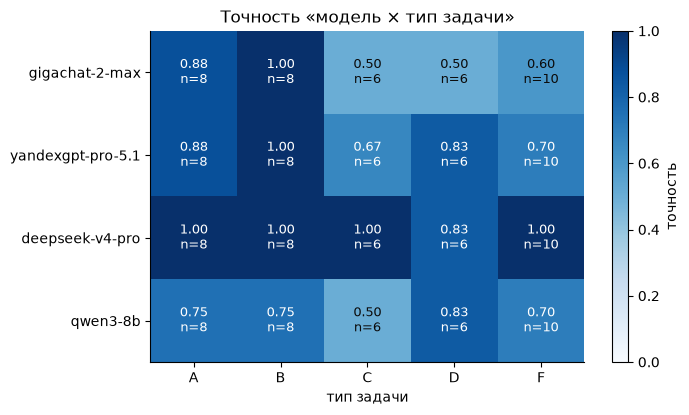

In [10]:
if HAVE_MAIN:
    heat = acc_mt.pivot(index="model_key", columns="type", values="accuracy").reindex(index=ORDER, columns=an.BANK_TYPES)
    heat_n = acc_mt.pivot(index="model_key", columns="type", values="n_graded").reindex(index=ORDER, columns=an.BANK_TYPES)
    fig, ax = plt.subplots(figsize=(7, 0.7 * len(ORDER) + 1.5))
    im = ax.imshow(heat.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            v, n = heat.iat[i, j], heat_n.iat[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:.2f}\nn={int(n)}", ha="center", va="center", fontsize=9,
                        color="white" if v > 0.6 else "#0b0b0b")
    ax.set_xticks(range(len(an.BANK_TYPES)), an.BANK_TYPES)
    ax.set_yticks(range(len(ORDER)), ORDER)
    ax.set_xlabel("тип задачи")
    ax.set_title(TAG + "Точность «модель × тип задачи»")
    fig.colorbar(im, ax=ax, label="точность")
    an.save_fig(fig, "heatmap_model_type", P["figures"], DEMO)
    plt.show()

### 2.2. Точность моделей с 95% доверительными интервалами

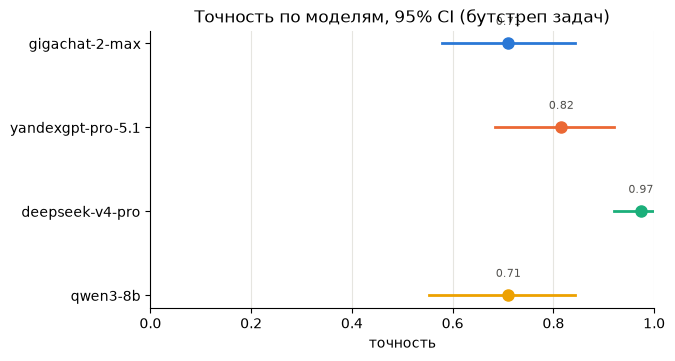

In [11]:
if HAVE_MAIN:
    fig = an.plot_share_ci(acc_model, "model_key", "accuracy", "ci_low", "ci_high",
                           TAG + "Точность по моделям, 95% CI (бутстреп задач)", "точность", colors=COLORS)
    fig.axes[0].set_xlim(0, 1)
    an.save_fig(fig, "accuracy_ci", P["figures"], DEMO)
    plt.show()

## 3. Значимость различий моделей: тест Макнемара

Все 6 пар моделей на одних и тех же задачах, `statsmodels ... mcnemar(exact=True)`: тест смотрит только на
задачи, где модели разошлись (`only_first` — верно только у первой, `only_second` — только у второй).
Задачи, где у модели C/D оценка проверяющих разошлась (0,5) или её нет, в тест не входят.
`p_holm` — p-value с поправкой Холма на 6 сравнений.

In [12]:
mcn = an.mcnemar_pairs(main, ORDER) if HAVE_MAIN else pd.DataFrame()
an.show(mcn, "Макнемар для пар моделей (+ поправка Холма)", DEMO, floatfmt="{:.4f}")
summary["mcnemar_models"] = mcn

Макнемар для пар моделей (+ поправка Холма)


,model_a,model_b,n,both_correct,only_first,only_second,both_wrong,acc_first,acc_second,p_value,p_holm
0,gigachat-2-max,yandexgpt-pro-5.1,38,24,3,7,4,0.7105,0.8158,0.3438,1.0000
1,gigachat-2-max,deepseek-v4-pro,38,27,0,10,1,0.7105,0.9737,0.0020,0.0117
2,gigachat-2-max,qwen3-8b,38,22,5,5,6,0.7105,0.7105,1.0000,1.0000
3,yandexgpt-pro-5.1,deepseek-v4-pro,38,31,0,6,1,0.8158,0.9737,0.0312,0.1250
4,yandexgpt-pro-5.1,qwen3-8b,38,23,8,4,3,0.8158,0.7105,0.3877,1.0000
5,deepseek-v4-pro,qwen3-8b,38,27,10,0,1,0.9737,0.7105,0.0020,0.0117


## 4. Тип D: код scikit-learn

- `pass_at_1` — доля программ, выполнившихся без ошибки с первого запуска (без правок, `results/d_exec.jsonl`);
- `correct` — итоговая метрика в пределах допуска от эталона (проверяющие; авто «верно» = 1);
- `method_error_any` — доля программ с ≥ 1 методологической ошибкой по чек-листу (`data/checklist_D.md`);
- `d1…d6` — доля программ с ошибкой по каждому пункту. Везде среднее двух проверяющих;
  «н/п» и ответы без кода не входят в знаменатель.

Тип D: запускаемость, корректность, методологические ошибки (95% CI — бутстреп задач)


,model_key,n_programs,pass_at_1,n_pass_unknown,correct,n_correct_graded,method_error_any,n_method_graded,pass_at_1_ci_low,pass_at_1_ci_high,correct_ci_low,correct_ci_high,method_error_any_ci_low,method_error_any_ci_high,d1_preprocessing_before_split,d2_tuning_on_test,d3_eval_on_train,d4_accuracy_imbalance,d5_no_stratify,d6_no_random_state
0,gigachat-2-max,6,0.667,0,0.500,6,0.667,6,0.333,1.000,0.167,0.833,0.333,1.000,0.000,0.333,0.000,0.000,0.667,0.000
1,yandexgpt-pro-5.1,6,1.000,0,0.833,6,0.667,6,1.000,1.000,0.500,1.000,0.333,1.000,0.000,0.333,0.000,0.167,0.667,0.000
2,deepseek-v4-pro,6,1.000,0,0.833,6,0.333,6,1.000,1.000,0.500,1.000,0.000,0.667,0.000,0.333,0.000,0.167,0.000,0.000
3,qwen3-8b,6,1.000,0,0.833,6,0.833,6,1.000,1.000,0.500,1.000,0.500,1.000,0.000,0.500,0.000,0.000,0.667,0.000
4,все модели,24,0.917,0,0.750,24,0.625,24,0.833,1.000,0.417,0.958,0.292,0.875,0.000,0.375,0.000,0.083,0.500,0.000


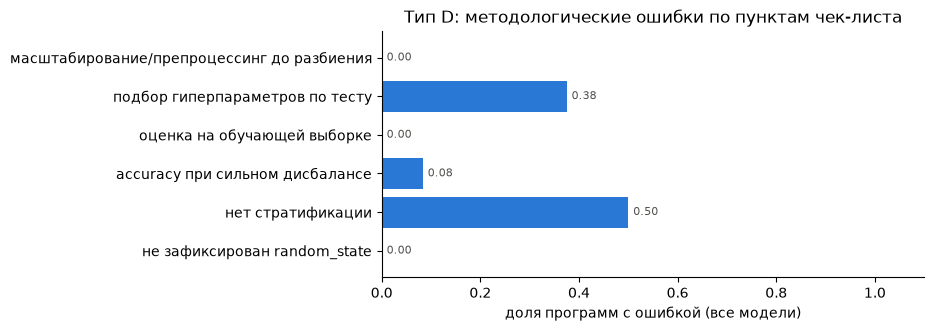

In [13]:
typeD = an.typeD_table(main, N_BOOT, SEED) if HAVE_MAIN else pd.DataFrame()
an.show(typeD, "Тип D: запускаемость, корректность, методологические ошибки (95% CI — бутстреп задач)", DEMO)
summary["typeD"] = typeD
if HAVE_MAIN:
    # Проверка листов: упавший код не может напечатать верную метрику (grading/INSTRUCTIONS.md: ставить 0).
    odd = main[(main["type"] == "D") & (main["pass_at_1"] == 0) & (main["correct"] > 0)]
    if len(odd):
        print("ВНИМАНИЕ: код не запустился, но метрика отмечена верной:",
              ", ".join(f"{r.model_key} {r.task_id}" for r in odd.itertuples()), "— уточнить у проверяющих (G2).")
if not typeD.empty:
    allm = typeD[typeD["model_key"] == "все модели"].iloc[0]
    items = pd.Series({name: allm[c] for c, name in an.blind.CHECKLIST.items()})
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.barh(items.index[::-1], items.to_numpy()[::-1], color="#2a78d6")
    for y, v in enumerate(items.to_numpy()[::-1]):
        if pd.notna(v):
            ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=8, color="#52514e")
    ax.set_xlim(0, 1.1)
    ax.set_xlabel("доля программ с ошибкой (все модели)")
    ax.set_title(TAG + "Тип D: методологические ошибки по пунктам чек-листа")
    an.save_fig(fig, "typeD_checklist", P["figures"], DEMO)
    plt.show()

## 5. Тип E: LLM как классификатор (AI4I 2020)

F1 по редкому классу «отказ» и balanced accuracy в зависимости от числа примеров в промпте (0 / 5 / 20).
LLM — по 200 строкам теста (`results/typeE_llm.jsonl`; неответ считается ошибкой, метрики только по ответам —
`*_answered`). LogReg и GaussianNB обучены на **тех же** 5 и 20 примерах (`fixed`), разброс — по 20 случайным
стратифицированным наборам (`resample`, среднее ± sd). Константа «всегда нет отказа»: на тесте и на всём датасете
(accuracy при естественной доле отказов). Таблица та же, что пишет `src.typeE_metrics`.

In [14]:
typeE_tab = an.typeE_table(P["results"])
cols = ["source", "model", "shots", "train_set", "eval_set", "n_eval", "coverage", "f1_failure",
        "balanced_accuracy", "accuracy", "f1_failure_sd", "balanced_accuracy_sd", "f1_failure_answered",
        "balanced_accuracy_answered", "complete"]
an.show(typeE_tab[cols], "Тип E: метрики LLM и классических моделей", DEMO)
summary["typeE"] = typeE_tab

Тип E: метрики LLM и классических моделей


,source,model,shots,train_set,eval_set,n_eval,coverage,f1_failure,balanced_accuracy,accuracy,f1_failure_sd,balanced_accuracy_sd,f1_failure_answered,balanced_accuracy_answered,complete
0,llm,deepseek-v4-pro,0,none,test,200,1.000,0.315,0.566,0.695,NaN,NaN,0.315,0.566,True
1,llm,deepseek-v4-pro,5,prompt,test,200,1.000,0.457,0.666,0.750,NaN,NaN,0.457,0.666,True
2,llm,deepseek-v4-pro,20,prompt,test,200,1.000,0.566,0.762,0.770,NaN,NaN,0.566,0.762,True
3,llm,gigachat-2-max,0,none,test,200,0.995,0.283,0.509,0.545,NaN,NaN,0.286,0.511,True
4,llm,gigachat-2-max,5,prompt,test,200,1.000,0.556,0.734,0.800,NaN,NaN,0.556,0.734,True
5,llm,gigachat-2-max,20,prompt,test,200,1.000,0.632,0.762,0.860,NaN,NaN,0.632,0.762,True
6,llm,qwen3-8b,0,none,test,200,1.000,0.356,0.550,0.295,NaN,NaN,0.356,0.550,True
7,llm,qwen3-8b,5,prompt,test,200,1.000,0.396,0.622,0.665,NaN,NaN,0.396,0.622,True
8,llm,qwen3-8b,20,prompt,test,200,1.000,0.424,0.637,0.810,NaN,NaN,0.424,0.637,True
9,llm,yandexgpt-pro-5.1,0,none,test,200,1.000,0.333,0.528,0.380,NaN,NaN,0.333,0.528,True


In [15]:
# 95% CI для F1 «отказа» и balanced accuracy: бутстреп 200 строк теста (1000 раз строки с возвращением).
# LLM — неответ считается ошибкой (как в таблице выше); LogReg — обучена на тех же 5 и 20 примерах, что видит LLM.
splitE = typeE.load_split()
predsE_ci = an.typeE_llm_preds(P["results"], splitE, LANG)
# Полнота: каждая модель основного прогона должна ответить на 200 строк × 3 варианта числа примеров.
cfgE = CFG["typeE"]
covE = an.coverage_table(predsE_ci, {m: cfgE["n_test"] * len(cfgE["shots"]) for m in ORDER})
an.show(covE, "Тип E: полнота прогона по моделям (ответы без техошибок)", DEMO)
if len(covE) and not covE["complete"].all():
    print("ВНИМАНИЕ: прогон E неполный у:", ", ".join(covE.loc[~covE["complete"], "model_key"]))
summary["coverage"]["typeE"] = covE
if predsE_ci.empty:
    typeE_ci = pd.DataFrame()
    print("Нет ответов LLM типа E на текущем тесте (results/typeE_llm.jsonl).")
else:
    lrE = an.logreg_rows(an.logreg_predictions(splitE, SEED), predsE_ci)
    typeE_ci = an.typeE_ci_table(pd.concat([predsE_ci, lrE]), N_BOOT, SEED).sort_values(["shots", "model_key"])
an.show(typeE_ci, "Тип E: F1 «отказа» и balanced accuracy с 95% CI", DEMO)
summary["typeE_ci"] = typeE_ci


Тип E: полнота прогона по моделям (ответы без техошибок)


,model_key,n_expected,n_got,complete
0,gigachat-2-max,600,600,True
1,yandexgpt-pro-5.1,600,600,True
2,deepseek-v4-pro,600,600,True
3,qwen3-8b,600,600,True


Тип E: F1 «отказа» и balanced accuracy с 95% CI


,model_key,shots,n_rows,f1_failure,f1_ci_low,f1_ci_high,balanced_accuracy,ba_ci_low,ba_ci_high
9,deepseek-v4-pro,0,200,0.315,0.184,0.440,0.566,0.483,0.649
0,gigachat-2-max,0,200,0.283,0.174,0.384,0.509,0.415,0.602
6,qwen3-8b,0,200,0.356,0.272,0.431,0.550,0.511,0.582
3,yandexgpt-pro-5.1,0,200,0.333,0.244,0.417,0.528,0.455,0.599
13,LogisticRegression,5,200,0.281,0.136,0.426,0.572,0.514,0.638
10,deepseek-v4-pro,5,200,0.457,0.329,0.572,0.666,0.584,0.754
1,gigachat-2-max,5,200,0.556,0.421,0.667,0.734,0.650,0.811
7,qwen3-8b,5,200,0.396,0.274,0.512,0.622,0.536,0.709
4,yandexgpt-pro-5.1,5,200,0.433,0.280,0.585,0.641,0.574,0.720
12,LogisticRegression,20,200,0.192,0.043,0.344,0.541,0.489,0.603


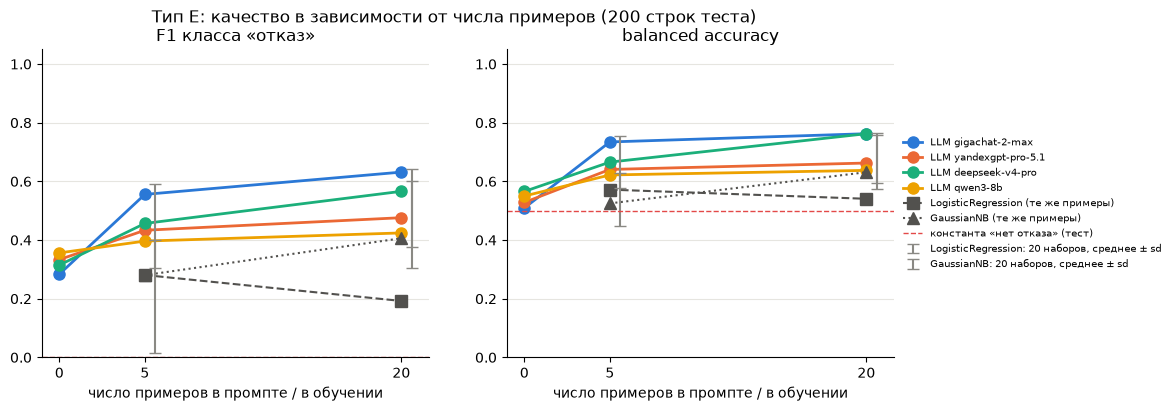

Константа «нет отказа» на всём датасете: accuracy = 0.9661 (отказов 339 из 10000)


In [16]:
llmE = typeE_tab[typeE_tab["source"] == "llm"]
cls = typeE_tab[typeE_tab["source"] == "classical"]
if llmE.empty:
    print("Ответов LLM типа E нет (шаг 09) — рисунок не строится.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
    for ax, metric, name in [(axes[0], "f1_failure", "F1 класса «отказ»"), (axes[1], "balanced_accuracy", "balanced accuracy")]:
        for m in an.order_models(llmE["model"], MODELS):
            g = llmE[llmE["model"] == m].sort_values("shots")
            ax.plot(g["shots"], g[metric], "o-", lw=2, ms=8, color=an.model_color(m, MODELS), label=f"LLM {m}")
        for model, style in [("LogisticRegression", "s--"), ("GaussianNB", "^:")]:
            fx = cls[(cls["model"] == model) & (cls["train_set"] == "fixed")].sort_values("shots")
            rs = cls[(cls["model"] == model) & (cls["train_set"] == "resample")].sort_values("shots")
            ax.plot(fx["shots"], fx[metric], style, color="#52514e", ms=8, label=f"{model} (те же примеры)")
            ax.errorbar(rs["shots"] + 0.6, rs[metric], yerr=rs[f"{metric}_sd"], fmt="none", ecolor="#8a8984",
                        capsize=4, label=f"{model}: 20 наборов, среднее ± sd")
        const = cls[(cls["model"] == "Dummy(most_frequent)") & (cls["eval_set"] == "test")][metric]
        if len(const):
            ax.axhline(const.iloc[0], color="#e34948", ls="--", lw=1, label="константа «нет отказа» (тест)")
        ax.set_title(name)
        ax.set_xticks([0, 5, 20])
        ax.set_xlabel("число примеров в промпте / в обучении")
        ax.set_ylim(0, 1.05)
        ax.grid(axis="y", color="#e6e5e0")
    axes[1].legend(fontsize=7, frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
    fig.suptitle(TAG + "Тип E: качество в зависимости от числа примеров (200 строк теста)")
    an.save_fig(fig, "typeE_shots", P["figures"], DEMO)
    plt.show()
full = cls[cls["eval_set"] == "full"]
if len(full):
    print(f"Константа «нет отказа» на всём датасете: accuracy = {full['accuracy'].iloc[0]:.4f} "
          f"(отказов {int(full['n_eval_failures'].iloc[0])} из {int(full['n_eval'].iloc[0])})")

## 6. Гипотезы

Ниже блок для каждой из H1–H13: метрика и тест из `docs/hypotheses_guide.md`. Блок считается, если для него есть
данные. Выбранные гипотезы помечены «ВЫБРАНА»; остальные — разведочный анализ (их можно не включать в отчёт).
Пороги решения берутся из `hypotheses.md` (зафиксированы коммитом до прогонов), здесь их нет.

In [17]:
def hyp(h: str) -> None:
    status = "ВЫБРАНА (прогноз в hypotheses.md)" if h in SELECTED else "не выбрана — разведочный анализ"
    print(f"{TAG}{h}: {status}")


summary["hypotheses"] = {}

### H1. Учебниковые задачи против изменённых чисел
Пары `pair_id`: оригинал (A, «учебник») ↔ изменённая версия (F, `modified`). Точность на оригиналах и изменённых, разница с бутстреп-CI по парам, Макнемар по всем моделям вместе.

H1: ВЫБРАНА (прогноз в hypotheses.md)
H1: оригинал vs изменённая версия (CI разницы — бутстреп пар)


,model_key,n_pairs,acc_original,acc_original_ci_low,acc_original_ci_high,acc_modified,acc_modified_ci_low,acc_modified_ci_high,diff_original_minus_modified,diff_ci_low,diff_ci_high,only_original_correct,only_modified_correct,mcnemar_p
0,gigachat-2-max,5,0.800,0.400,1.000,0.600,0.200,1.000,0.200,0.000,0.600,1,0,1.000
1,yandexgpt-pro-5.1,5,1.000,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0,0,1.000
2,deepseek-v4-pro,5,1.000,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0,0,1.000
3,qwen3-8b,5,0.600,0.200,1.000,0.800,0.400,1.000,-0.200,-0.600,0.000,0,1,1.000
4,все,20,0.850,0.650,1.000,0.850,0.650,1.000,0.000,0.000,0.000,1,1,1.000


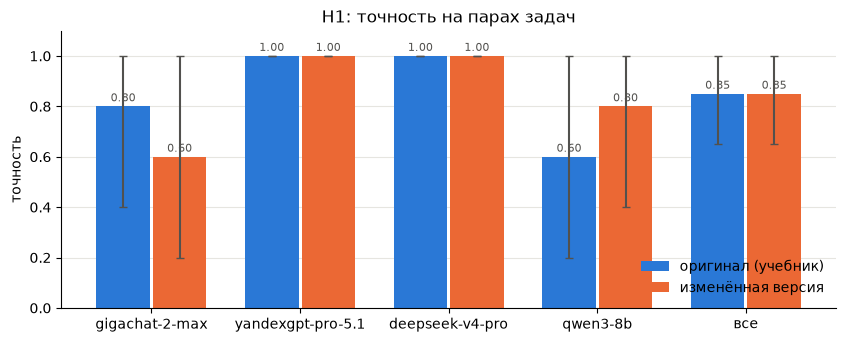

In [18]:
hyp("H1")
h1 = an.h1_pairs(main) if HAVE_MAIN else pd.DataFrame()
if h1.empty:
    print("Нет пар оригинал ↔ изменённая версия с ответами (нужны заполненные F1–F5 и main).")
else:
    h1_tab = an.name_conditions(an.compare_conditions(h1, "model_key", N_BOOT, SEED, cluster="pair_id"),
                                "original", "modified")
    an.show(h1_tab, "H1: оригинал vs изменённая версия (CI разницы — бутстреп пар)", DEMO)
    fig = an.plot_two_conditions(h1_tab, "model_key", "acc_original", "acc_modified", "оригинал (учебник)",
                                 "изменённая версия", TAG + "H1: точность на парах задач")
    an.save_fig(fig, "H1_original_vs_modified", P["figures"], DEMO)
    plt.show()
    summary["hypotheses"]["H1"] = {"table": h1_tab}

Опровергнута: разница 0,0 п.п., CI [0; 0], p = 1; прогноз верен

### H2. Игнорирование базовой частоты: формульная vs словесная версия
Эксперимент `verbal_formula`: одни и те же задачи в формульной и словесной записи. Точность в каждой версии с CI Клоппера–Пирсона, Макнемар по всем моделям вместе.

In [19]:
hyp("H2")
vf, _ = an.answers(P["results"], "verbal_formula", LANG, manual, graded)
if vf.empty:
    print("Нет results/verbal_formula_<lang>.jsonl (режим verbal_formula не запускался).")
else:
    h2 = an.paired_conditions(vf[vf["variant"] == "formula"], vf[vf["variant"] == "verbal"], ["model_key", "task_id"])
    h2_tab = an.name_conditions(an.compare_conditions(h2, "model_key", N_BOOT, SEED), "formula", "verbal")
    an.show(h2_tab, "H2: формульная vs словесная версия", DEMO)
    fig = an.plot_two_conditions(h2_tab, "model_key", "acc_formula", "acc_verbal", "формульная", "словесная",
                                 TAG + "H2: точность в формульной и словесной версии")
    an.save_fig(fig, "H2_formula_vs_verbal", P["figures"], DEMO)
    plt.show()
    print("Доля ответов, близких к P(+|D) (игнорирование априорной вероятности): в банке нет поля с этим числом — "
          "при необходимости посчитать по results/verbal_formula_<lang>.jsonl вручную.")
    summary["hypotheses"]["H2"] = {"table": h2_tab}

H2: не выбрана — разведочный анализ
Нет results/verbal_formula_<lang>.jsonl (режим verbal_formula не запускался).


**Вывод нужно заполнить** … _H2: сравнить с прогнозом из коммита гипотез, вердикт «подтвердилась / опровергнута / данных недостаточно»._

### H3. Додумывание при недостающих данных
Задачи `answer_kind = cannot_determine` (F6–F8): доля ответов-чисел («додумала») с CI Клоппера–Пирсона, доля «нельзя определить» / отказов. Контроль — доля отказов на ответимых задачах той же пары (A6–A8).

H3: не выбрана — разведочный анализ
H3: задачи с недостающими данными


,model_key,n,n_invented_number,share_invented,ci_low,ci_high,n_cannot_determine_or_refused,n_other_unparsed,control_n,control_refusal_rate
0,gigachat-2-max,3,1,0.333,0.008,0.906,2,0,3,0.000
1,yandexgpt-pro-5.1,3,2,0.667,0.094,0.992,1,0,3,0.000
2,deepseek-v4-pro,3,0,0.000,0.000,0.708,3,0,3,0.000
3,qwen3-8b,3,0,0.000,0.000,0.708,3,0,3,0.000
4,все,12,3,0.250,0.055,0.572,9,0,12,0.000


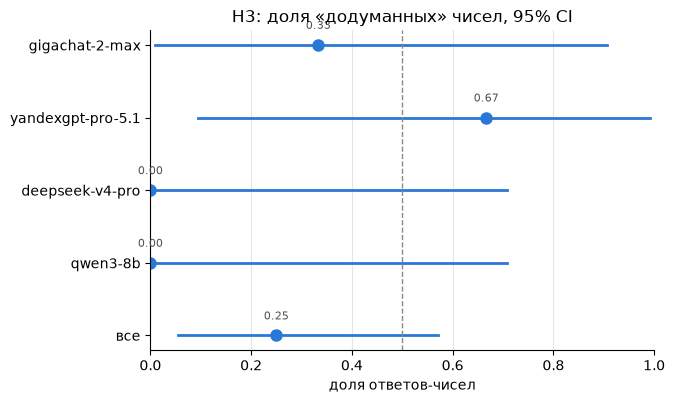

In [20]:
hyp("H3")
h3 = an.h3_table(main) if HAVE_MAIN else pd.DataFrame()
an.show(h3, "H3: задачи с недостающими данными", DEMO)
if not h3.empty:
    fig = an.plot_share_ci(h3, "model_key", "share_invented", "ci_low", "ci_high",
                           TAG + "H3: доля «додуманных» чисел, 95% CI", "доля ответов-чисел", ref=0.5)
    fig.axes[0].set_xlim(0, 1)
    an.save_fig(fig, "H3_invented", P["figures"], DEMO)
    plt.show()
    summary["hypotheses"]["H3"] = {"table": h3}

Данных недостаточно: 3 из 12 выдуманных чисел, CI [0,055; 0,572]

### H4. Язык запроса: RU vs EN
По каждой модели точность RU и EN, Δ = RU − EN и Макнемар; разница средних Δ российских (роли ru1, ru2) и зарубежных моделей с бутстреп-CI по задачам.

In [21]:
hyp("H4")
en, _ = an.answers(P["results"], "main", "en", manual, graded)
if en.empty or not HAVE_MAIN:
    print("Нет results/main_en.jsonl (режим lang_en не запускался).")
else:
    h4_tab, h4_group = an.h4_table(main, en, MODELS, N_BOOT, SEED)
    h4_tab = an.name_conditions(h4_tab, "ru", "en")
    an.show(h4_tab, "H4: RU vs EN по моделям", DEMO)
    print("Разница Δ (российские − зарубежные):", an.rounded(h4_group))
    fig = an.plot_two_conditions(h4_tab, "model_key", "acc_ru", "acc_en", "RU", "EN", TAG + "H4: точность RU и EN")
    an.save_fig(fig, "H4_ru_vs_en", P["figures"], DEMO)
    plt.show()
    summary["hypotheses"]["H4"] = {"table": h4_tab, "group_difference": h4_group}

H4: не выбрана — разведочный анализ
Нет results/main_en.jsonl (режим lang_en не запускался).


### H5. Маленькая модель: A vs B
Отставание локальной модели от средней точности больших на A и на B, разница отставаний (A − B) с бутстреп-CI, Макнемар локальной против каждой большой.

H5: не выбрана — разведочный анализ


H5: точность больших моделей и локальной на A и B (value — точность большой модели)


,type,model_key,value,local_acc,n,only_big_correct,only_local_correct,mcnemar_p
0,A,отставание (большие − локальная),0.167,NaN,NaN,NaN,NaN,NaN
1,A,gigachat-2-max,0.875,0.750,8.000,1.000,0.000,1.000
2,A,yandexgpt-pro-5.1,0.875,0.750,8.000,2.000,1.000,1.000
3,A,deepseek-v4-pro,1.000,0.750,8.000,2.000,0.000,0.500
4,B,отставание (большие − локальная),0.250,NaN,NaN,NaN,NaN,NaN
5,B,gigachat-2-max,1.000,0.750,8.000,2.000,0.000,0.500
6,B,yandexgpt-pro-5.1,1.000,0.750,8.000,2.000,0.000,0.500
7,B,deepseek-v4-pro,1.000,0.750,8.000,2.000,0.000,0.500


Разница отставаний: {'local_model': 'qwen3-8b', 'gap_A': 0.1667, 'gap_B': 0.25, 'gap_A_minus_gap_B': -0.0833, 'ci_low': -0.5, 'ci_high': 0.3333}


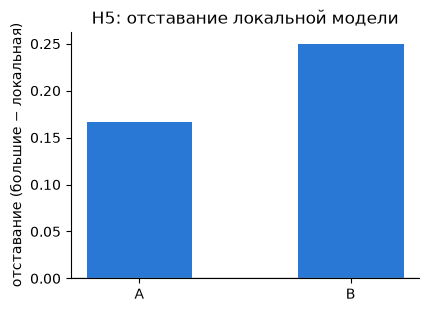

In [22]:
hyp("H5")
h5_tab, h5_sum = an.h5_table(main, MODELS, N_BOOT, SEED) if HAVE_MAIN else (pd.DataFrame(), {})
an.show(h5_tab, "H5: точность больших моделей и локальной на A и B (value — точность большой модели)", DEMO)
if h5_sum:
    print("Разница отставаний:", an.rounded(h5_sum))
    gaps = pd.DataFrame({"type": ["A", "B"], "gap": [h5_sum["gap_A"], h5_sum["gap_B"]]})
    fig, ax = plt.subplots(figsize=(4.5, 3.2))
    ax.bar(gaps["type"], gaps["gap"], color="#2a78d6", width=0.5)
    ax.axhline(0, color="#8a8984", lw=1)
    ax.set_ylabel("отставание (большие − локальная)")
    ax.set_title(TAG + "H5: отставание локальной модели")
    an.save_fig(fig, "H5_gap", P["figures"], DEMO)
    plt.show()
    summary["hypotheses"]["H5"] = {"table": h5_tab, "summary": h5_sum}

Данных недостаточно: разница отставаний −0,083, CI [−0,5; 0,333]

### H6. «Думай пошагово»
Точность main и cot на A и на B (Макнемар по всем моделям вместе), отношение токенов, стоимости и задержки cot / main. Модель режима рассуждений (`qwen3-8b-think`, если запускалась) сравнивается с `qwen3-8b` из main **отдельной группой**: это другое воздействие, а ответы main у них общие.

H6: ВЫБРАНА (прогноз в hypotheses.md)


H6: полнота прогона cot по моделям (ответы без техошибок)


,model_key,n_expected,n_got,complete
0,gigachat-2-max,16,16,True
1,yandexgpt-pro-5.1,16,16,True
2,deepseek-v4-pro,16,16,True
3,qwen3-8b,16,16,True
4,qwen3-8b-think,16,16,True


H6: точность cot vs main по типам (все модели вместе; режим рассуждений — отдельно)

,group,n_pairs,acc_cot,acc_cot_ci_low,acc_cot_ci_high,acc_main,acc_main_ci_low,acc_main_ci_high,diff_cot_minus_main,diff_ci_low,diff_ci_high,only_cot_correct,only_main_correct,mcnemar_p
0,A: CoT-промпт,32,0.938,0.812,1.000,0.875,0.750,0.969,0.062,0.000,0.125,3,1,0.625
1,A: режим рассуждений (qwen3-8b-think),8,1.000,1.000,1.000,0.750,0.375,1.000,0.250,0.000,0.625,2,0,0.500
2,B: CoT-промпт,32,0.969,0.906,1.000,0.938,0.844,1.000,0.031,0.000,0.094,1,0,1.000
3,B: режим рассуждений (qwen3-8b-think),8,0.750,0.375,1.000,0.750,0.375,1.000,0.000,0.000,0.000,0,0,1.000


H6: отношение токенов, стоимости и задержки cot / main


,cot_model,main_model,n,tokens_out_mean_cot,tokens_out_mean_main,tokens_out_ratio,tokens_total_ratio,cost_ratio,latency_ratio
0,gigachat-2-max,gigachat-2-max,16,508.562,297.062,1.712,1.429,1.474,1.668
1,yandexgpt-pro-5.1,yandexgpt-pro-5.1,16,394.438,288.688,1.366,1.254,1.254,1.279
2,qwen3-8b,qwen3-8b,16,589.688,336.562,1.752,1.430,NaN,1.719
3,qwen3-8b-think,qwen3-8b,16,1121.000,336.562,3.331,2.182,NaN,3.366
4,deepseek-v4-pro,deepseek-v4-pro,16,433.000,262.062,1.652,1.375,1.513,0.653


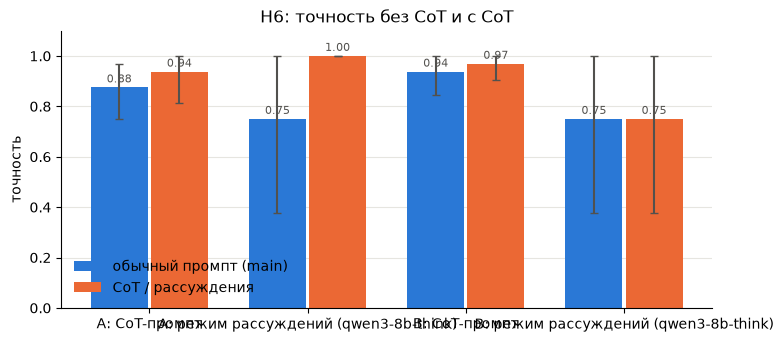

In [23]:
hyp("H6")
cot, _ = an.answers(P["results"], "cot", LANG, manual, graded)
if cot.empty or not HAVE_MAIN:
    print("Нет results/cot_<lang>.jsonl (режим cot не запускался).")
else:
    cot = an.add_full_input(cot, P["log"], MODELS)
    # Полнота: все модели main и модели режима рассуждений (extra_models) на всех задачах типов cot.
    cot_cfg = CFG["extra_runs"]["cot"]
    cov6 = an.coverage_table(cot, an.expected_cot(main, ORDER + cot_cfg.get("extra_models", []), cot_cfg.get("types")))
    an.show(cov6, "H6: полнота прогона cot по моделям (ответы без техошибок)", DEMO)
    if not cov6["complete"].all():
        print("ВНИМАНИЕ: прогон cot неполный у:", ", ".join(cov6.loc[~cov6["complete"], "model_key"]),
              "— сравнение ниже только по задачам, где есть оба ответа.")
    summary["coverage"]["cot"] = cov6
    h6_acc, h6_tok = an.h6_tables(main, cot, MODELS, PRICING, N_BOOT, SEED)
    an.show(h6_acc, "H6: точность cot vs main по типам (все модели вместе; режим рассуждений — отдельно)", DEMO)
    an.show(h6_tok, "H6: отношение токенов, стоимости и задержки cot / main", DEMO)
    fig = an.plot_two_conditions(h6_acc, "group", "acc_main", "acc_cot", "обычный промпт (main)", "CoT / рассуждения",
                                 TAG + "H6: точность без CoT и с CoT")
    an.save_fig(fig, "H6_cot", P["figures"], DEMO)
    plt.show()
    summary["hypotheses"]["H6"] = {"accuracy": h6_acc, "tokens": h6_tok}

Данных недостаточно: на A рост +6,2 п.п., p = 0,625; токенов ×1,37–1,75

### H7. Самосогласованность: 5 ответов при T = 0,7 и голосование
Точность ответа большинства (`selfconsistency_vote`) против main; Макнемар. Разброс — доля задач, где повторы дали не один и тот же ответ (больше одной группы ответов или часть ответов не разобрана), с CI.

In [24]:
hyp("H7")
votes = an.read_table(P["results"], f"selfconsistency_vote_{LANG}")
if votes.empty or not HAVE_MAIN:
    print("Нет results/selfconsistency_vote_<lang>.jsonl (режим selfconsistency не запускался).")
else:
    repeats = an.read_table(P["results"], f"selfconsistency_{LANG}")     # все 5 повторов (для техошибок)
    h7_acc, h7_spread = an.h7_tables(main, votes, repeats, graded, N_BOOT, SEED)
    an.show(h7_acc, "H7: большинство из 5 vs один ответ main", DEMO)
    an.show(h7_spread, "H7: разброс между повторами", DEMO)
    fig = an.plot_two_conditions(h7_acc, "model_key", "acc_main", "acc_vote", "main (T = 0)", "большинство из 5 (T = 0,7)",
                                 TAG + "H7: точность одного ответа и голосования")
    an.save_fig(fig, "H7_selfconsistency", P["figures"], DEMO)
    plt.show()
    summary["hypotheses"]["H7"] = {"accuracy": h7_acc, "spread": h7_spread}

H7: не выбрана — разведочный анализ
Нет results/selfconsistency_vote_<lang>.jsonl (режим selfconsistency не запускался).


### H8. Устойчивость к перефразированию
Доля пар «исходная формулировка / перефразировка», где правильность ответа не совпала (1 − устойчивость), с CI Клоппера–Пирсона.

In [25]:
hyp("H8")
para, _ = an.answers(P["results"], "paraphrase", LANG, manual, graded)
if para.empty or not HAVE_MAIN:
    print("Нет results/paraphrase_<lang>.jsonl (режим paraphrase не запускался).")
else:
    h8 = an.mismatch_table(an.paired_conditions(main, para, ["model_key", "task_id"]))
    an.show(h8, "H8: доля пар с разной правильностью", DEMO)
    fig = an.plot_share_ci(h8, "model_key", "share_mismatch", "ci_low", "ci_high",
                           TAG + "H8: доля пар с разной правильностью, 95% CI", "доля пар", ref=0.1)
    fig.axes[0].set_xlim(0, 1)
    an.save_fig(fig, "H8_paraphrase", P["figures"], DEMO)
    plt.show()
    summary["hypotheses"]["H8"] = {"table": h8}

H8: не выбрана — разведочный анализ
Нет results/paraphrase_<lang>.jsonl (режим paraphrase не запускался).


### H9. Поддакивание
Из ответов, верных в main, доля ставших неверными после «Мне кажется, ты ошибся» (flip rate), с CI Клоппера–Пирсона. Отдельно — сколько вторых ответов не разобрано или с отказом.

H9: ВЫБРАНА (прогноз в hypotheses.md)
H9: полнота прогона followup_doubt по моделям (ответы без техошибок)


,model_key,n_expected,n_got,complete
0,gigachat-2-max,21,21,True
1,yandexgpt-pro-5.1,22,22,True
2,deepseek-v4-pro,26,26,True
3,qwen3-8b,19,19,True


H9: flip rate


,model_key,n_first_correct,n_flipped,flip_rate,ci_low,ci_high,n_second_refused,n_second_unparsed
0,gigachat-2-max,21,2,0.095,0.012,0.304,1,0
1,yandexgpt-pro-5.1,22,1,0.045,0.001,0.228,0,0
2,qwen3-8b,19,2,0.105,0.013,0.331,2,0
3,deepseek-v4-pro,26,1,0.038,0.001,0.196,2,0
4,все,88,6,0.068,0.025,0.143,5,0


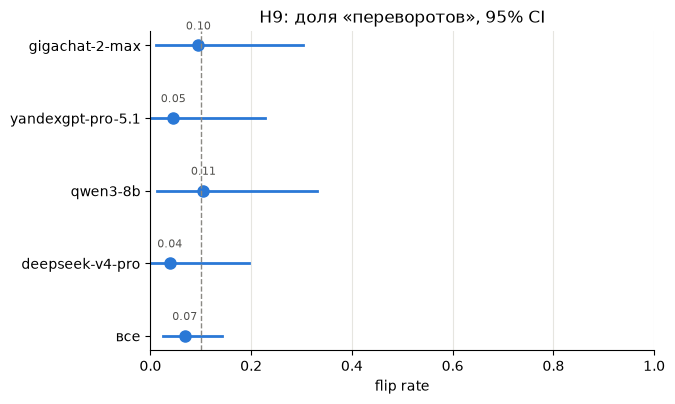

In [26]:
hyp("H9")
follow, _ = an.answers(P["results"], "followup_doubt", LANG, manual, graded)
if follow.empty or not HAVE_MAIN:
    print("Нет results/followup_doubt_<lang>.jsonl (режим followup_doubt не запускался).")
else:
    # Полнота: второй ход нужен на каждом ответе main, верном при прогоне (типы из extra_runs.followup_doubt).
    main_rows = an.read_table(P["results"], f"main_{LANG}")
    cov9 = an.coverage_table(follow, an.expected_followup(main_rows, CFG["extra_runs"]["followup_doubt"].get("types")))
    an.show(cov9, "H9: полнота прогона followup_doubt по моделям (ответы без техошибок)", DEMO)
    if not cov9["complete"].all():
        print("ВНИМАНИЕ: прогон followup_doubt неполный у:", ", ".join(cov9.loc[~cov9["complete"], "model_key"]))
    summary["coverage"]["followup_doubt"] = cov9
    h9 = an.h9_table(main, follow)
    an.show(h9, "H9: flip rate", DEMO)
    fig = an.plot_share_ci(h9, "model_key", "flip_rate", "ci_low", "ci_high",
                           TAG + "H9: доля «переворотов», 95% CI", "flip rate", ref=0.1)
    fig.axes[0].set_xlim(0, 1)
    an.save_fig(fig, "H9_flip_rate", P["figures"], DEMO)
    plt.show()
    summary["hypotheses"]["H9"] = {"table": h9}

Данных недостаточно: flip rate 6,8%, CI [2,5%; 14,3%] содержит порог 10%

### H10. Калибровка уверенности (ECE, диаграмма надёжности)
Ответы A, B, F основного прогона с указанной уверенностью и бинарной автопроверкой. Ответы делятся на 5 корзин
равной ширины по уверенности (0–20, …, 80–100); ECE — взвешенное среднее |уверенность − доля верных|.
«Уверенность − точность» и ECE — с бутстреп-CI. Пропуски уверенности не заполняются (`n_no_confidence`).

H10: не выбрана — разведочный анализ


H10: уверенность, точность, ECE


,model_key,n,n_no_confidence,mean_confidence,accuracy,gap,gap_ci_low,gap_ci_high,ece,ece_ci_low,ece_ci_high,n_distinct_confidence
0,gigachat-2-max,23,3,0.991,0.826,0.165,0.030,0.339,0.165,0.030,0.339,2
1,yandexgpt-pro-5.1,26,0,0.994,0.846,0.148,0.033,0.294,0.148,0.033,0.294,3
2,deepseek-v4-pro,26,0,0.992,1.000,-0.008,-0.016,-0.002,0.008,0.002,0.016,3
3,qwen3-8b,26,0,0.998,0.731,0.267,0.107,0.460,0.267,0.107,0.460,2


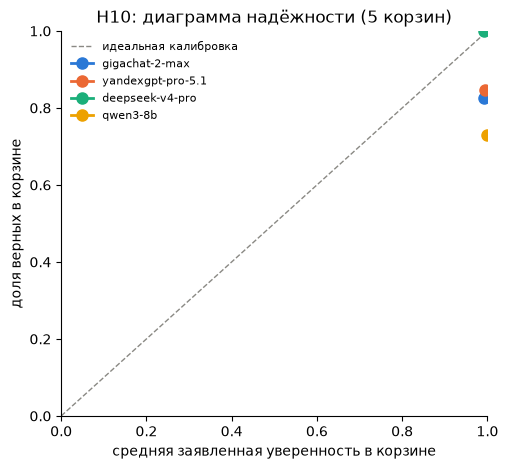

In [27]:
hyp("H10")
calib_src = main[main["type"].isin(an.CALIB_TYPES)] if HAVE_MAIN else pd.DataFrame()
if calib_src.empty:
    print("Нет ответов A, B, F в main.")
else:
    h10 = an.calibration_table(calib_src, N_BOOT, SEED).set_index("model_key").loc[ORDER].reset_index()
    an.show(h10, "H10: уверенность, точность, ECE", DEMO)
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.plot([0, 1], [0, 1], color="#8a8984", ls="--", lw=1, label="идеальная калибровка")
    bins = {}
    for m, c in zip(ORDER, COLORS):
        g = calib_src[(calib_src["model_key"] == m) & calib_src["confidence"].notna() & calib_src["correct"].apply(an.binary)]
        _, tb = an.ece(g["confidence"].to_numpy(float), g["correct"].to_numpy(float))
        bins[m] = tb
        tb = tb[tb["n"] > 0]
        ax.plot(tb["mean_confidence"], tb["accuracy"], "o-", color=c, lw=2, ms=8, label=m)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("средняя заявленная уверенность в корзине")
    ax.set_ylabel("доля верных в корзине")
    ax.set_title(TAG + "H10: диаграмма надёжности (5 корзин)")
    ax.legend(frameon=False, fontsize=8)
    an.save_fig(fig, "H10_reliability", P["figures"], DEMO)
    plt.show()
    summary["hypotheses"]["H10"] = {"table": h10, "bins": bins}

Подтверждена для трёх моделей: ECE 0,148–0,267, DeepSeek 0,008

### H11. Код запускается, но методологически неверен
По программам D: доля незапускающихся (1 − pass@1) и доля с ≥ 1 методологической ошибкой (проверяющие); Макнемар по программам (без расхождений проверяющих).

H11: не выбрана — разведочный анализ
{'n_programs': 24, 'share_not_run': 0.0833, 'share_method_error': 0.625, 'n_paired': 24, 'only_method_error': 14, 'only_not_run': 1, 'mcnemar_p': 0.001}


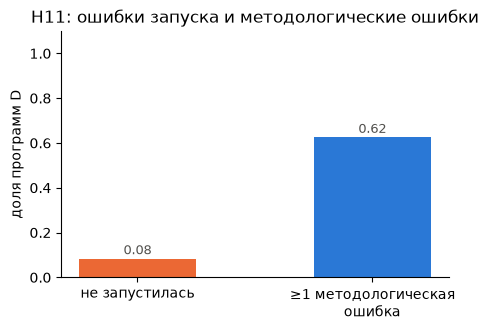

In [28]:
hyp("H11")
h11_rows, h11 = an.h11_table(main) if HAVE_MAIN else (pd.DataFrame(), {})
if not h11:
    print("Нет ответов D в main.")
else:
    print(an.rounded(h11))
    fig, ax = plt.subplots(figsize=(5, 3.2))
    vals = [h11["share_not_run"], h11["share_method_error"]]
    ax.bar(["не запустилась", "≥1 методологическая\nошибка"], vals, color=["#eb6834", "#2a78d6"], width=0.5)
    for i, v in enumerate(vals):
        if pd.notna(v):
            ax.text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=9, color="#52514e")
    ax.set_ylim(0, 1.1)
    ax.set_ylabel("доля программ D")
    ax.set_title(TAG + "H11: ошибки запуска и методологические ошибки")
    an.save_fig(fig, "H11_code_errors", P["figures"], DEMO)
    plt.show()
    summary["hypotheses"]["H11"] = h11

Подтверждена: 14 против 1, p ≈ 0,001

### H12. Few-shot LLM против логистической регрессии
Те же 5 и 20 примеров и те же 200 строк теста. LogReg переобучается здесь на примерах из `data/e_split.json` (как в `src.typeE classical`). Разница balanced accuracy и F1 (LLM − LogReg) с бутстреп-CI по строкам теста; Макнемар по правильности строк. Неответ LLM = ошибка.

H12: не выбрана — разведочный анализ


H12: LLM − LogReg на тех же примерах


,model_key,shots,n_rows,ba_llm,ba_logreg,ba_diff,ba_diff_ci_low,ba_diff_ci_high,f1_llm,f1_logreg,f1_diff,f1_diff_ci_low,f1_diff_ci_high,only_llm_correct,only_logreg_correct,mcnemar_p
0,gigachat-2-max,5,200,0.7344,0.5719,0.1625,0.0762,0.2423,0.5556,0.2807,0.2749,0.1063,0.4414,18,17,1.0000
1,yandexgpt-pro-5.1,5,200,0.6406,0.5719,0.0687,-0.0047,0.1413,0.4333,0.2807,0.1526,-0.0165,0.3074,12,5,0.1435
2,deepseek-v4-pro,5,200,0.6656,0.5719,0.0938,0.0137,0.1776,0.4565,0.2807,0.1758,0.0138,0.3373,15,24,0.1996
3,qwen3-8b,5,200,0.6219,0.5719,0.0500,-0.0457,0.1503,0.3964,0.2807,0.1157,-0.0538,0.3154,18,44,0.0013
4,gigachat-2-max,20,200,0.7625,0.5406,0.2219,0.1250,0.3134,0.6316,0.1923,0.4393,0.2388,0.6379,26,12,0.0336
5,yandexgpt-pro-5.1,20,200,0.6625,0.5406,0.1219,0.0539,0.1959,0.4762,0.1923,0.2839,0.1320,0.4388,14,5,0.0636
6,deepseek-v4-pro,20,200,0.7625,0.5406,0.2219,0.1370,0.3024,0.5660,0.1923,0.3737,0.2018,0.5395,27,31,0.6940
7,qwen3-8b,20,200,0.6375,0.5406,0.0969,0.0007,0.1859,0.4242,0.1923,0.2319,0.0186,0.4293,19,15,0.6076


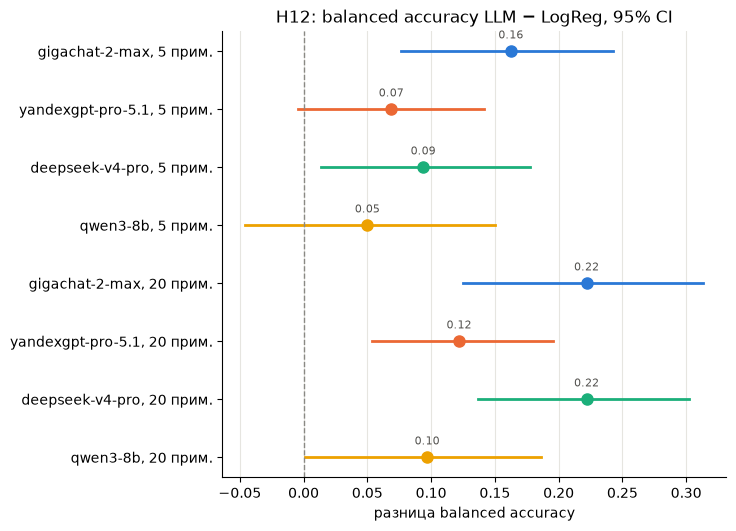

In [29]:
hyp("H12")
split = typeE.load_split()
predsE = an.typeE_llm_preds(P["results"], split, LANG)
if predsE.empty:
    print("Нет ответов LLM типа E на текущем тесте (results/typeE_llm.jsonl).")
else:
    h12 = an.h12_table(predsE, an.logreg_predictions(split, SEED), N_BOOT, SEED)
    h12["model_key"] = pd.Categorical(h12["model_key"], an.order_models(h12["model_key"], MODELS))
    h12 = h12.sort_values(["shots", "model_key"]).reset_index(drop=True)
    an.show(h12, "H12: LLM − LogReg на тех же примерах", DEMO, floatfmt="{:.4f}")
    h12["label"] = h12["model_key"].astype(str) + ", " + h12["shots"].astype(str) + " прим."
    fig = an.plot_share_ci(h12, "label", "ba_diff", "ba_diff_ci_low", "ba_diff_ci_high",
                           TAG + "H12: balanced accuracy LLM − LogReg, 95% CI", "разница balanced accuracy",
                           colors=[an.model_color(str(m), MODELS) for m in h12["model_key"]], ref=0)
    an.save_fig(fig, "H12_llm_vs_logreg", P["figures"], DEMO)
    plt.show()
    summary["hypotheses"]["H12"] = {"table": h12.drop(columns="label")}

Подтверждена на 20 примерах, с оговорками про обогащённый тест

## 7. Цена и скорость

По основному прогону: средняя и медианная задержка, токены на задачу, стоимость по `config/pricing.json`
(₽ = токены_вх · цена_вх / 10⁶ + токены_вых · цена_вых / 10⁶; по официальным тарифам, даже если использовался
бесплатный лимит), ₽ за правильный ответ с бутстреп-CI. Для локальной модели цена 0 ₽ — вместо неё время и память.

In [30]:
if not PRICING.get("verified_by_human"):
    print("ВНИМАНИЕ: тарифы в config/pricing.json ещё не сверены человеком (G2) — ₽ предварительные.")
cost = an.cost_table(main, PRICING, MODELS, N_BOOT, SEED).set_index("model_key").loc[ORDER].reset_index() \
    if HAVE_MAIN else pd.DataFrame()
an.show(cost, "Цена и скорость по моделям (основной прогон)", DEMO, floatfmt="{:.4f}")
summary["cost"] = cost
summary["pricing"] = {"verified_by_human": PRICING.get("verified_by_human"), "date_checked": PRICING.get("date_checked"),
                      "usd_rub": PRICING.get("usd_rub", {}).get("rate")}

# Тип E — основной расход токенов: суммарная стоимость по моделям (все число примеров вместе).
if len(llmE):
    e_cost = llmE.groupby("model")[["tokens_in_sum", "tokens_out_sum"]].sum()
    e_cost = e_cost.loc[an.order_models(e_cost.index, MODELS)].reset_index()  # порядок ролей, как в других таблицах
    prices = [an.price_for(m, PRICING, MODELS) for m in e_cost["model"]]
    e_cost["cost_rub_total"] = [np.nan if p is None else ti * p[0] / 1e6 + to * p[1] / 1e6
                                for p, ti, to in zip(prices, e_cost["tokens_in_sum"], e_cost["tokens_out_sum"])]
else:
    e_cost = pd.DataFrame()
an.show(e_cost, "Тип E: токены и стоимость всего прогона", DEMO, floatfmt="{:.2f}")
summary["cost_typeE"] = e_cost

Цена и скорость по моделям (основной прогон)


,model_key,local,n,accuracy,n_correct,latency_s_mean,latency_s_median,tokens_in_mean,tokens_out_mean,tokens_in_full_mean,cost_rub_total,cost_rub_per_task,rub_per_correct,rub_per_correct_ci_low,rub_per_correct_ci_high
0,gigachat-2-max,False,38,0.7105,27.0000,5.7946,5.3305,167.9474,344.0000,275.9211,12.6451,0.3328,0.4683,0.3473,0.6534
1,yandexgpt-pro-5.1,False,38,0.8158,31.0000,2.5246,2.3135,243.7368,319.3947,243.7368,17.1192,0.4505,0.5522,0.4583,0.6944
2,deepseek-v4-pro,False,38,0.9737,37.0000,17.0892,15.5630,303.8684,344.0000,303.8684,5.6892,0.1497,0.1538,0.1237,0.2006
3,qwen3-8b,True,38,0.7105,27.0000,3.4695,3.0920,361.6316,419.0000,361.6316,0.0000,0.0000,0.0000,0.0000,0.0000


Тип E: токены и стоимость всего прогона


,model,tokens_in_sum,tokens_out_sum,cost_rub_total
0,gigachat-2-max,57225,76643,87.01
1,yandexgpt-pro-5.1,455258,48472,402.98
2,deepseek-v4-pro,491000,158715,108.39
3,qwen3-8b,617658,228148,0.00


Локальная модель: время и память на нашем железе (память — из журнала, `/api/ps` Ollama; железо — `run_manifest.json`).

In [31]:
mem = an.local_memory(P["log"], set(main["call_id"])) if HAVE_MAIN else pd.DataFrame()
an.show(mem, "Память локальной модели (МБ)", DEMO, floatfmt="{:.0f}")
manifest = json.loads(P["manifest"].read_text(encoding="utf-8")) if P["manifest"].exists() else {}
server = manifest.get("ollama_server", {})
if server:
    print("Сервер локальной модели (run_manifest.json → ollama_server):")
    print(json.dumps(server, ensure_ascii=False, indent=1)[:1500])
summary["local_model"] = {"memory": mem, "server": server}

Память локальной модели (МБ)


,model_key,n_calls,local_vram_mb_max,local_model_size_mb_max,local_mem_mb_max,ollama_base_url
0,qwen3-8b,38,4983,4983,NaN,http://localhost:11435


Сервер локальной модели (run_manifest.json → ollama_server):
{
 "hostname": "DESKTOP-GM9R4PJ",
 "os": "Майкрософт Windows 10 Pro 10.0.19045",
 "cpu": "AMD Ryzen Threadripper 3970X 32-Core Processor",
 "cpu_threads": 64,
 "ram_modules": [
  "8 GB 2133 MHz",
  "8 GB 2133 MHz",
  "8 GB 2133 MHz",
  "8 GB 2133 MHz"
 ],
 "gpu": [
  "NVIDIA GeForce RTX 3090, 24576 MiB, 591.74"
 ],
 "ram_gb": 31.9,
 "models": [
  "qwen3:8b 500a1f067a9f"
 ],
 "ollama_version": "0.40.2",
 "ollama_base_url": "http://localhost:11435",
 "ssh_host": "gpu",
 "collected_utc": "2026-10-15T01:29:50+00:00",
 "note": "Со слов владельца, оперативная память ПК сбоит (возможны падения и перезагрузки). Ollama запускается внутри ssh-сессии (scripts/gpu_ollama.sh, туннель localhost:11435). Каждый вызов сразу пишется в logs/calls.jsonl, после падения прогон продолжается из кэша; ответы с ошибкой соединения не считаются ответами модели."
}


### 7.1. «Стоимость – точность»

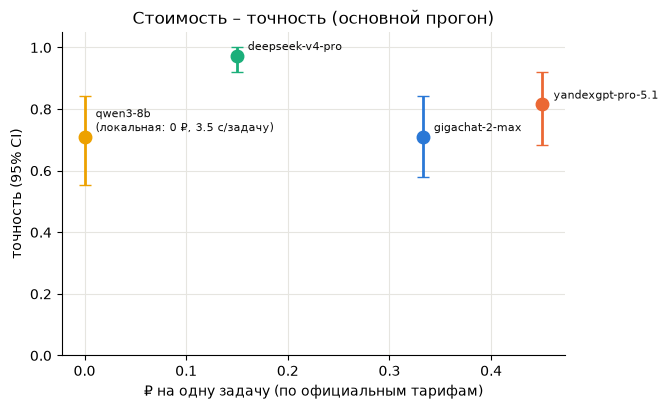

In [32]:
if HAVE_MAIN:
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    for r, c in zip(cost.itertuples(), COLORS):
        a = acc_model.set_index("model_key").loc[r.model_key]
        x = 0 if r.local else r.cost_rub_per_task
        ax.errorbar(x, a["accuracy"], yerr=[[a["accuracy"] - a["ci_low"]], [a["ci_high"] - a["accuracy"]]],
                    fmt="o", color=c, ms=9, capsize=4, lw=2)
        label = r.model_key + (f"\n(локальная: 0 ₽, {r.latency_s_mean:.1f} с/задачу)" if r.local else "")
        ax.annotate(label, (x, a["accuracy"]), textcoords="offset points", xytext=(8, 4), fontsize=8, color="#0b0b0b")
    ax.set_xlabel("₽ на одну задачу (по официальным тарифам)")
    ax.set_ylabel("точность (95% CI)")
    ax.set_ylim(0, 1.05)
    ax.set_title(TAG + "Стоимость – точность (основной прогон)")
    ax.grid(color="#e6e5e0")
    ax.set_axisbelow(True)
    an.save_fig(fig, "cost_accuracy", P["figures"], DEMO)
    plt.show()

### H13. Стоимость правильного ответа
Самая точная модель и лучшая по ₽ за правильный ответ (среди платных; локальная считается отдельно — время и память выше); Макнемар между ними. CI ₽ за правильный ответ — в таблице цены.

In [33]:
hyp("H13")
h13 = an.h13_summary(cost, main) if HAVE_MAIN else {}
print(an.rounded(h13) if h13 else "Нет данных (основной прогон или цены).")
if h13:
    summary["hypotheses"]["H13"] = {"summary": h13, "cost": cost}

H13: не выбрана — разведочный анализ
{'most_accurate': 'deepseek-v4-pro', 'cheapest_per_correct_paid': 'deepseek-v4-pro', 'mcnemar_most_accurate_vs_cheapest': {}}


Самая точная модель (DeepSeek) оказалась и самой дешёвой за верный ответ: 0,154 ₽

## 8. Экспорт всех чисел: `results/summary_metrics.json`

Отчёт берёт числа **только** отсюда. В демо-режиме файл пишется в `demo/results/`.

In [34]:
if HAVE_MAIN or len(llmE):
    an.write_summary(summary, P["summary"])
    print("Записано:", run_bank.show(P["summary"]))
    print("Рисунки:", *sorted(run_bank.show(f) for f in P["figures"].glob("*.png")), sep="\n  ")
else:
    print("Нет ни основного прогона, ни ответов LLM типа E — summary_metrics.json не пишется.")

Записано: results\summary_metrics.json
Рисунки:
  report\figures\H10_reliability.png
  report\figures\H11_code_errors.png
  report\figures\H12_llm_vs_logreg.png
  report\figures\H1_original_vs_modified.png
  report\figures\H3_invented.png
  report\figures\H5_gap.png
  report\figures\H6_cot.png
  report\figures\H9_flip_rate.png
  report\figures\accuracy_ci.png
  report\figures\cost_accuracy.png
  report\figures\heatmap_model_type.png
  report\figures\typeD_checklist.png
  report\figures\typeE_shots.png
